# Cloud Dynamics — Empirical Analysis
Virtualenv-based Jupyter analysis of completed experiments.

In [49]:
from pathlib import Path
import os, pandas as pd, matplotlib.pyplot as plt
RESULTS=Path('/home/ali/kuliah/homelab-fp-rm77/kubernetes/research/cloud-dynamics-experiments/results').resolve()
OUTPUTS=Path('../outputs').resolve(); OUTPUTS.mkdir(parents=True,exist_ok=True)
print('Results:',RESULTS)


Results: /home/ali/kuliah/homelab-fp-rm77/kubernetes/research/cloud-dynamics-experiments/results


In [50]:
experiments=sorted(p for p in RESULTS.iterdir() if p.is_dir() and (p/'combined.csv').exists())
pd.DataFrame({'index':range(len(experiments)),'experiment':[p.name for p in experiments]})


,index,experiment
0,0,ramp-20261027T084301Z-r2


In [51]:
EXPERIMENT_INDEX=0
EXPERIMENT=experiments[EXPERIMENT_INDEX]
df=pd.read_csv(EXPERIMENT/'combined.csv')
df.head()


,timestamp_epoch,elapsed_s,target_rps,sent,success,failed,achieved_rps,mean_latency_ms,p95_latency_ms,CPU_USAGE,...,READY_PODS,LINKERD_REQUEST_RATE,LINKERD_GOODPUT_RPS,LINKERD_SUCCESS_RATE,LINKERD_FAILED_RPS,LINKERD_LATENCY_P50,LINKERD_LATENCY_P95,LINKERD_LATENCY_P99,LINKERD_THROUGHPUT_BYTES,LINKERD_TCP_CONNECTIONS
0,1.793148e+09,1.003,43.107,26,26,0,26.0,19.621,24.345,0.000851,...,2.0,0.40,0.40,1.0,NaN,0.50000,0.950000,0.990000,109.85,4.0
1,1.793148e+09,2.001,76.029,59,51,0,59.0,41.264,115.706,0.000856,...,2.0,1.85,1.85,1.0,NaN,13.62069,19.362069,19.872414,953.65,8.0
2,1.793148e+09,3.003,109.090,93,55,0,93.0,316.069,501.898,0.000861,...,2.0,1.85,1.85,1.0,NaN,13.62069,19.362069,19.872414,953.65,8.0
3,1.793148e+09,4.003,142.084,125,57,0,125.0,695.431,916.279,0.000866,...,2.0,1.85,1.85,1.0,NaN,13.62069,19.362069,19.872414,953.65,8.0
4,1.793148e+09,5.001,175.047,159,50,0,159.0,1197.011,1424.447,0.003350,...,2.0,1.85,1.85,1.0,NaN,13.62069,19.362069,19.872414,953.65,8.0


In [52]:
df.describe(include='all').T


,count,mean,std,min,25%,50%,75%,max
timestamp_epoch,31.0,1.793148e+09,4.611039e+01,1.793148e+09,1.793148e+09,1.793148e+09,1.793148e+09,1.793148e+09
elapsed_s,31.0,2.363594e+01,4.611068e+01,1.003000e+00,8.502000e+00,1.600100e+01,2.350000e+01,2.676720e+02
target_rps,31.0,5.369803e+02,2.982530e+02,4.310700e+01,2.905650e+02,5.380420e+02,7.855050e+02,1.000000e+03
sent,31.0,4.834839e+02,2.944109e+02,0.000000e+00,2.395000e+02,4.870000e+02,7.285000e+02,9.680000e+02
success,31.0,4.833226e+02,2.386663e+03,2.600000e+01,5.400000e+01,5.600000e+01,5.750000e+01,1.334300e+04
failed,31.0,1.612903e-01,8.980265e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
achieved_rps,31.0,4.834839e+02,2.944109e+02,0.000000e+00,2.395000e+02,4.870000e+02,7.285000e+02,9.680000e+02
mean_latency_ms,31.0,3.655596e+03,1.585530e+03,1.962100e+01,3.358988e+03,4.543827e+03,4.563463e+03,4.655943e+03
p95_latency_ms,31.0,3.820618e+03,1.584251e+03,2.434500e+01,3.625119e+03,4.686208e+03,4.704494e+03,4.836462e+03
CPU_USAGE,31.0,1.233915e-01,1.110883e-01,8.514616e-04,5.682849e-02,8.663365e-02,1.953153e-01,5.186742e-01


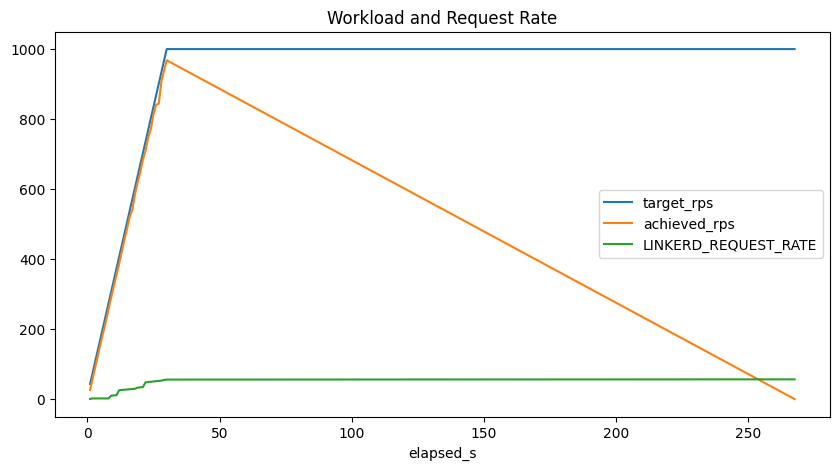

In [53]:
cols=[c for c in ['target_rps','achieved_rps','LINKERD_REQUEST_RATE'] if c in df]
if cols: df.plot(x='elapsed_s',y=cols,figsize=(10,5),title='Workload and Request Rate'); plt.show()


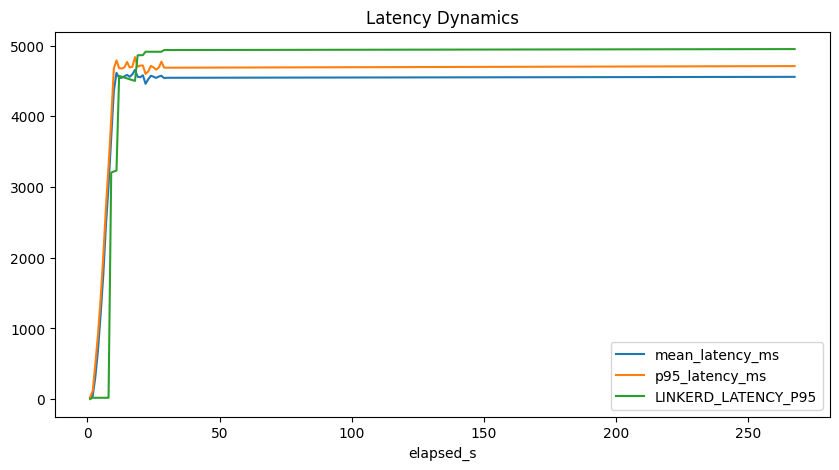

In [54]:
cols=[c for c in ['mean_latency_ms','p95_latency_ms','LINKERD_LATENCY_P95'] if c in df]
if cols: df.plot(x='elapsed_s',y=cols,figsize=(10,5),title='Latency Dynamics'); plt.show()


In [55]:
numeric=df.select_dtypes(include='number'); drivers=[c for c in ['target_rps','achieved_rps'] if c in numeric]
numeric.corr()[drivers] if drivers else pd.DataFrame()


,target_rps,achieved_rps
timestamp_epoch,0.462802,-0.120568
elapsed_s,0.462735,-0.120643
target_rps,1.000000,0.824001
sent,0.824001,1.000000
success,0.289180,-0.303714
failed,0.288120,-0.304781
achieved_rps,0.824001,1.000000
mean_latency_ms,0.777662,0.714868
p95_latency_ms,0.767836,0.706036
CPU_USAGE,0.888807,0.493250


In [56]:
OUT=OUTPUTS/EXPERIMENT.name; OUT.mkdir(parents=True,exist_ok=True)
df.describe().T.to_csv(OUT/'notebook-descriptive-statistics.csv')
print('Saved:',OUT)


Saved: /home/ali/kuliah/homelab-fp-rm77/kubernetes/research/cloud-dynamics-analysis-venv/outputs/ramp-20261027T084301Z-r2
